____
__Universidad Tecnológica Nacional, Buenos Aires__<br/>
__Ingeniería Industrial__<br/>
__Cátedra de Ciencia de Datos - Curso I5521 - Turno jueves noche__<br/>
__Trabajo Práctico Final: Bank Subscription - Preprocesamiento de datos__<br/>
__Elaborado por: Grupo 7__
____

## Objetivo

Este notebook reúne todas las manipulaciones que transforman el dataset original (`bank_subscription.csv`) en los conjuntos de entrenamiento y test que usan los modelos de machine learning. Las decisiones de cada paso se justifican en el análisis exploratorio (`clusterai_ricardomartin_echague_eda.ipynb`). Aquí las aplicamos en orden y de forma reproducible.

El pipeline sigue estos pasos:

1. Carga del dataset y eliminación de `Last Contact Duration` (*data leakage*).
2. División en train y test, **antes** de cualquier imputación o escalado.
3. Imputación de valores faltantes, con parámetros calculados solo sobre train.
4. Transformación logarítmica de las variables más asimétricas.
5. Codificación *one-hot* de las variables categóricas.
6. Estandarización de las variables numéricas, con parámetros calculados solo sobre train.
7. Verificación final y exportación de los conjuntos procesados a la carpeta `datos_procesados/`.

Para correrlo, solo se necesita el archivo `bank_subscription.csv` en la misma carpeta que este notebook.

## Importamos las librerías necesarias

In [4]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

## 1. Carga del dataset

Cargamos el dataset original y eliminamos `Last Contact Duration`. Como se explicó en el EDA, la duración de la llamada solo se conoce una vez que esta terminó, es decir, cuando ya se sabe si el cliente suscribió o no. Usarla para predecir sería *data leakage*.

In [5]:
df = pd.read_csv("bank_subscription.csv", delimiter=";")
print(f"Dataset original: {df.shape[0]:,} filas y {df.shape[1]} columnas")

df = df.drop(columns=["Last Contact Duration"])
print(f"Sin Last Contact Duration: {df.shape[0]:,} filas y {df.shape[1]} columnas")

Dataset original: 45,211 filas y 17 columnas
Sin Last Contact Duration: 45,211 filas y 16 columnas


## 2. División en train y test

Dividimos el dataset **antes** de imputar y escalar. La imputación (medianas y modas) y la estandarización (media y desvío) aprenden parámetros de los datos. Si los calculáramos sobre el dataset completo, información del conjunto de test se filtraría al entrenamiento y la evaluación final resultaría optimista. Por eso, todos los parámetros se calculan únicamente sobre train y luego se aplican, sin recalcular, a test.

Usamos una partición 80/20 **estratificada** según `Subscription`: como el target está desbalanceado (11,7% de suscripciones), la estratificación garantiza que ambos conjuntos mantengan esa proporción. Fijamos `random_state=42` para que la partición sea reproducible.

In [6]:
target = "Subscription"

x = df.drop(columns=[target])
y = df[target]

xtrain, xtest, ytrain, ytest = train_test_split(x, y, test_size=0.20, random_state=42, stratify=y)

# Copiamos para trabajar sobre DataFrames independientes
xtrain = xtrain.copy()
xtest = xtest.copy()

print(f"Train: {xtrain.shape[0]:,} filas | proporción de suscripciones: {ytrain.mean():.2%}")
print(f"Test:  {xtest.shape[0]:,} filas | proporción de suscripciones: {ytest.mean():.2%}")

Train: 36,168 filas | proporción de suscripciones: 11.70%
Test:  9,043 filas | proporción de suscripciones: 11.70%


## 3. Imputación de valores faltantes

Aplicamos la estrategia definida en el EDA. Allí verificamos que los faltantes están dispersos y no se asocian con la suscripción, lo que respalda imputar con medidas simples:

| Variable | Estrategia | Justificación |
|---|---|---|
| `Credit`, `Personal Loan`, `Marital Status` | Moda | Una categoría es claramente dominante |
| `Housing Loan` | Nueva categoría `unknown` | Distribución equilibrada entre `yes` y `no`: la moda introduciría mucho error |
| `Job`, `Education` | Categoría `unknown` existente | La variable ya contempla esa categoría |
| `Age`, `Balance (euros)` | Mediana | Distribuciones asimétricas con outliers: la mediana es robusta |
| `Pdays` | `-1` si `Previous = 0`; si no, mediana de los contactados | En los datos informados, `Pdays = -1` coincide siempre con `Previous = 0` |

Todos los parámetros (modas y medianas) se calculan sobre `xtrain`.

In [7]:
# Guardamos la cantidad de nulos antes de imputar, para compararla al final
nulos_antes = pd.DataFrame({"train": xtrain.isnull().sum(), "test": xtest.isnull().sum()})
nulos_antes = nulos_antes[(nulos_antes["train"] > 0) | (nulos_antes["test"] > 0)]
print("Nulos ANTES de imputar:")
nulos_antes

Nulos ANTES de imputar:


,train,test
Age,3925,1048
Job,3956,1017
Marital Status,3939,1034
Education,3945,1028
Credit,3975,998
Balance (euros),3992,981
Housing Loan,6162,1524
Personal Loan,6217,1469
Pdays,6250,1436


In [8]:
# --- Parámetros aprendidos SOLO de train ---
cols_moda = ["Credit", "Personal Loan", "Marital Status"]
cols_unknown = ["Housing Loan", "Job", "Education"]
cols_mediana = ["Age", "Balance (euros)"]

modas = {col: xtrain[col].mode()[0] for col in cols_moda}
medianas = {col: xtrain[col].median() for col in cols_mediana}
mediana_pdays = xtrain.loc[xtrain["Pdays"] != -1, "Pdays"].median()

print("Modas (train):", modas)
print("Medianas (train):", medianas)
print("Mediana de Pdays entre clientes contactados (train):", mediana_pdays)

Modas (train): {'Credit': 'no', 'Personal Loan': 'no', 'Marital Status': 'married'}
Medianas (train): {'Age': np.float64(39.0), 'Balance (euros)': np.float64(450.0)}
Mediana de Pdays entre clientes contactados (train): 194.0


In [9]:
def imputar(datos):
    """Imputa los faltantes con los parámetros aprendidos de train."""
    datos = datos.copy()

    for col in cols_moda:
        datos[col] = datos[col].fillna(modas[col])

    for col in cols_unknown:
        datos[col] = datos[col].fillna("unknown")

    for col in cols_mediana:
        datos[col] = datos[col].fillna(medianas[col])

    # Pdays (1): si nunca fue contactado (Previous == 0), el valor correcto es el código -1
    nunca_contactado = datos["Pdays"].isna() & (datos["Previous"] == 0)
    datos.loc[nunca_contactado, "Pdays"] = -1
    # Pdays (2): para el resto, mediana de los clientes contactados en train
    datos["Pdays"] = datos["Pdays"].fillna(mediana_pdays)

    return datos


xtrain = imputar(xtrain)
xtest = imputar(xtest)

# Verificación: nulos antes y después de imputar, por columna
verificacion = pd.DataFrame({
    "train antes": nulos_antes["train"],
    "train después": xtrain[nulos_antes.index].isnull().sum(),
    "test antes": nulos_antes["test"],
    "test después": xtest[nulos_antes.index].isnull().sum(),
})
print(f"Nulos totales después de imputar: train = {xtrain.isnull().sum().sum()} | test = {xtest.isnull().sum().sum()}")
verificacion

Nulos totales después de imputar: train = 0 | test = 0


,train antes,train después,test antes,test después
Age,3925,0,1048,0
Job,3956,0,1017,0
Marital Status,3939,0,1034,0
Education,3945,0,1028,0
Credit,3975,0,998,0
Balance (euros),3992,0,981,0
Housing Loan,6162,0,1524,0
Personal Loan,6217,0,1469,0
Pdays,6250,0,1436,0


## 4. Transformación logarítmica

En el EDA vimos que `Balance (euros)`, `Campaign` y `Previous` son muy asimétricas (skew de 8,6, 4,9 y 41,9, respectivamente) y tienen valores extremos. Decidimos no eliminar esos outliers, porque son valores reales del negocio. En su lugar, comprimimos la escala con una transformación logarítmica. Así, los valores extremos pierden peso en los modelos sensibles a la escala (regresión logística, KNN, SVM) y en PCA, sin perder información. Los árboles no se ven afectados por esta transformación, ya que es monótona y no cambia el orden de los valores.

- `Campaign` y `Previous`: `log(1 + x)`. Sumamos 1 porque `Previous` vale 0 para la mayoría de los clientes.
- `Balance (euros)`: tiene saldos negativos, para los que el logaritmo no está definido. Usamos la variante con signo, `sign(x) · log(1 + |x|)`.

Esta transformación no aprende parámetros de los datos, por lo que se aplica igual a train y test sin riesgo de filtración.

In [10]:
def transformar_log(datos):
    datos = datos.copy()
    datos["Balance_log"] = np.sign(datos["Balance (euros)"]) * np.log1p(np.abs(datos["Balance (euros)"]))
    datos["Campaign_log"] = np.log1p(datos["Campaign"])
    datos["Previous_log"] = np.log1p(datos["Previous"])
    return datos.drop(columns=["Balance (euros)", "Campaign", "Previous"])


skew_antes = xtrain[["Balance (euros)", "Campaign", "Previous"]].apply(skew)

xtrain = transformar_log(xtrain)
xtest = transformar_log(xtest)

skew_despues = xtrain[["Balance_log", "Campaign_log", "Previous_log"]].apply(skew)

pd.DataFrame({
    "variable original": skew_antes.index,
    "skew original": skew_antes.values.round(2),
    "variable transformada": skew_despues.index,
    "skew transformada": skew_despues.values.round(2),
})

,variable original,skew original,variable transformada,skew transformada
0,Balance (euros),9.03,Balance_log,-1.76
1,Campaign,4.94,Campaign_log,1.33
2,Previous,45.03,Previous_log,2.54


La asimetría de `Campaign` y `Previous` se reduce de forma marcada. En `Previous`, el valor transformado sigue siendo asimétrico porque el 81,7% de los clientes tiene `Previous = 0`, algo que ninguna transformación puede corregir. Aun así, el máximo pasa de 275 a ≈5,6, por lo que ese valor extremo deja de dominar la escala. En `Balance_log`, el skew negativo refleja el grupo de saldos negativos: la variable pasa a tener dos grupos bien definidos (saldos negativos y positivos), en lugar de una cola de más de 100.000 €.

## 5. Codificación de variables categóricas

Los modelos de scikit-learn requieren variables numéricas. Transformamos las categóricas con *one-hot encoding* (`pd.get_dummies`): cada categoría pasa a ser una columna binaria (0/1).

Usamos `drop_first=True`, que elimina una categoría por variable. La categoría eliminada queda representada cuando todas las demás valen 0. Si conserváramos todas, las columnas de cada variable sumarían siempre 1 y serían perfectamente colineales (la llamada *trampa de las variables dummy*), lo que afecta a modelos como la regresión logística.

Las dummies se generan sobre train, y test se reordena con las mismas columnas. Así se garantiza que ambos conjuntos tengan exactamente la misma estructura, incluso si alguna categoría poco frecuente no apareciera en uno de ellos.

In [11]:
cols_categoricas = ["Job", "Marital Status", "Education", "Credit", "Housing Loan",
                    "Personal Loan", "Contact", "Last Contact Month", "Poutcome"]

for col in cols_categoricas:
    print(f"{col}: {xtrain[col].nunique()} categorías -> {sorted(xtrain[col].unique())}")

Job: 12 categorías -> ['admin.', 'blue-collar', 'entrepreneur', 'housemaid', 'management', 'retired', 'self-employed', 'services', 'student', 'technician', 'unemployed', 'unknown']
Marital Status: 3 categorías -> ['divorced', 'married', 'single']
Education: 4 categorías -> ['primary', 'secondary', 'tertiary', 'unknown']
Credit: 2 categorías -> ['no', 'yes']
Housing Loan: 3 categorías -> ['no', 'unknown', 'yes']
Personal Loan: 2 categorías -> ['no', 'yes']
Contact: 3 categorías -> ['cellular', 'telephone', 'unknown']
Last Contact Month: 12 categorías -> ['apr', 'aug', 'dec', 'feb', 'jan', 'jul', 'jun', 'mar', 'may', 'nov', 'oct', 'sep']
Poutcome: 4 categorías -> ['failure', 'other', 'success', 'unknown']


In [12]:
xtrain = pd.get_dummies(xtrain, columns=cols_categoricas, drop_first=True, dtype=int)
xtest = pd.get_dummies(xtest, columns=cols_categoricas, drop_first=True, dtype=int)

# Test con exactamente las mismas columnas (y en el mismo orden) que train
columnas_faltantes = set(xtrain.columns) - set(xtest.columns)
columnas_extra = set(xtest.columns) - set(xtrain.columns)
print(f"Columnas de train ausentes en test: {columnas_faltantes or 'ninguna'}")
print(f"Columnas de test ausentes en train: {columnas_extra or 'ninguna'}")
xtest = xtest.reindex(columns=xtrain.columns, fill_value=0)

print(f"\nDimensiones luego de la codificación: train {xtrain.shape} | test {xtest.shape}")

Columnas de train ausentes en test: ninguna
Columnas de test ausentes en train: ninguna

Dimensiones luego de la codificación: train (36168, 42) | test (9043, 42)


## 6. Estandarización de variables numéricas

Estandarizamos las variables numéricas continuas con `StandardScaler`, que les resta la media y las divide por el desvío estándar: z = (x - μ) / σ. Así, todas quedan en una escala comparable (media 0 y desvío 1). Esto es necesario para los modelos basados en distancias (KNN, SVM), para la regresión logística regularizada y para PCA, que de otro modo estarían dominados por las variables de mayor magnitud.

- El scaler se ajusta (`fit`) **solo con train** y luego se aplica (`transform`) a train y a test.
- Las dummies no se escalan: ya están en escala 0/1 y conservan su interpretación.

In [13]:
cols_numericas = ["Age", "Balance_log", "Last Contact Day", "Campaign_log", "Pdays", "Previous_log"]

scaler = StandardScaler().fit(xtrain[cols_numericas])

xtrain[cols_numericas] = scaler.transform(xtrain[cols_numericas])
xtest[cols_numericas] = scaler.transform(xtest[cols_numericas])

pd.DataFrame({
    "media train": xtrain[cols_numericas].mean(),
    "desvío train": xtrain[cols_numericas].std(),
    "media test": xtest[cols_numericas].mean(),
    "desvío test": xtest[cols_numericas].std(),
}).round(3)

,media train,desvío train,media test,desvío test
Age,0.0,1.0,0.009,0.987
Balance_log,-0.0,1.0,-0.008,1.008
Last Contact Day,0.0,1.0,-0.007,0.994
Campaign_log,-0.0,1.0,0.000,1.001
Pdays,0.0,1.0,0.007,1.012
Previous_log,-0.0,1.0,0.008,1.002


En train, las variables quedan con media 0 y desvío 1 por construcción. En test, los valores son cercanos pero no exactos, lo cual es esperable: se usaron la media y el desvío de train, tal como ocurriría con datos nuevos en producción.

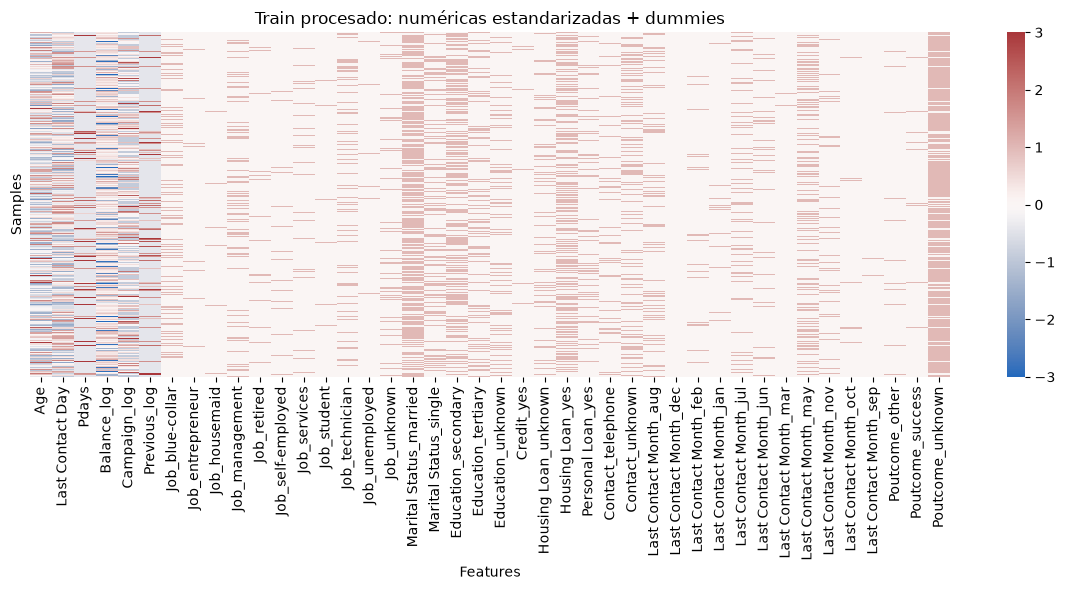

In [14]:
fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(xtrain, vmin=-3, vmax=3, cmap="vlag", ax=ax)
ax.set_title("Train procesado: numéricas estandarizadas + dummies")
ax.set_xlabel("Features")
ax.set_ylabel("Samples")
ax.set_yticks([])
plt.tight_layout()
plt.show()

## 7. Verificación final

Antes de exportar, verificamos que los conjuntos estén listos para el modelado.

In [15]:
assert xtrain.isnull().sum().sum() == 0 and xtest.isnull().sum().sum() == 0, "Quedan nulos"
assert list(xtrain.columns) == list(xtest.columns), "Train y test tienen columnas distintas"
assert all(np.issubdtype(t, np.number) for t in xtrain.dtypes), "Hay columnas no numéricas"
assert len(xtrain) == len(ytrain) and len(xtest) == len(ytest), "x e y no coinciden en filas"

print("Todas las verificaciones pasaron.\n")
print(f"xtrain: {xtrain.shape} | ytrain: {ytrain.shape} | proporción clase 1: {ytrain.mean():.2%}")
print(f"xtest:  {xtest.shape}  | ytest:  {ytest.shape}  | proporción clase 1: {ytest.mean():.2%}")
print(f"\nVariables predictoras ({xtrain.shape[1]}):")
print(list(xtrain.columns))

Todas las verificaciones pasaron.

xtrain: (36168, 42) | ytrain: (36168,) | proporción clase 1: 11.70%
xtest:  (9043, 42)  | ytest:  (9043,)  | proporción clase 1: 11.70%

Variables predictoras (42):
['Age', 'Last Contact Day', 'Pdays', 'Balance_log', 'Campaign_log', 'Previous_log', 'Job_blue-collar', 'Job_entrepreneur', 'Job_housemaid', 'Job_management', 'Job_retired', 'Job_self-employed', 'Job_services', 'Job_student', 'Job_technician', 'Job_unemployed', 'Job_unknown', 'Marital Status_married', 'Marital Status_single', 'Education_secondary', 'Education_tertiary', 'Education_unknown', 'Credit_yes', 'Housing Loan_unknown', 'Housing Loan_yes', 'Personal Loan_yes', 'Contact_telephone', 'Contact_unknown', 'Last Contact Month_aug', 'Last Contact Month_dec', 'Last Contact Month_feb', 'Last Contact Month_jan', 'Last Contact Month_jul', 'Last Contact Month_jun', 'Last Contact Month_mar', 'Last Contact Month_may', 'Last Contact Month_nov', 'Last Contact Month_oct', 'Last Contact Month_sep', 'P

## 8. Exportación

Guardamos los cuatro conjuntos en la carpeta `datos_procesados/`. Conservamos el índice original del dataset para poder rastrear cada fila hasta el registro de origen.

In [16]:
os.makedirs("datos_procesados", exist_ok=True)

xtrain.to_csv("datos_procesados/xtrain.csv")
xtest.to_csv("datos_procesados/xtest.csv")
ytrain.to_csv("datos_procesados/ytrain.csv")
ytest.to_csv("datos_procesados/ytest.csv")

for archivo in sorted(os.listdir("datos_procesados")):
    tamaño = os.path.getsize(os.path.join("datos_procesados", archivo)) / 1e6
    print(f"datos_procesados/{archivo}  ({tamaño:.1f} MB)")

datos_procesados/xtest.csv  (1.8 MB)
datos_procesados/xtrain.csv  (7.2 MB)
datos_procesados/ytest.csv  (0.1 MB)
datos_procesados/ytrain.csv  (0.3 MB)


Desde el notebook de machine learning, los conjuntos se cargan así:

```python
xtrain = pd.read_csv("datos_procesados/xtrain.csv", index_col=0)
xtest = pd.read_csv("datos_procesados/xtest.csv", index_col=0)
ytrain = pd.read_csv("datos_procesados/ytrain.csv", index_col=0)["Subscription"]
ytest = pd.read_csv("datos_procesados/ytest.csv", index_col=0)["Subscription"]
```

## Resumen

| Paso | Transformación | Ajustado sobre |
|---|---|---|
| 1 | Eliminación de `Last Contact Duration` (*data leakage*) | — |
| 2 | Partición 80/20 estratificada (`random_state=42`) | — |
| 3 | Imputación: moda, mediana, categoría `unknown` y regla de `Pdays` | Train |
| 4 | Logaritmo de `Balance (euros)` (con signo), `Campaign` y `Previous` | — (no aprende parámetros) |
| 5 | *One-hot encoding* con `drop_first=True` | Train (estructura de columnas) |
| 6 | Estandarización de las 6 variables numéricas | Train |

El resultado son dos matrices con 42 variables predictoras, sin nulos y con la misma estructura, listas para entrenar y evaluar los modelos.